<a href="https://colab.research.google.com/github/AnnaAkhlamova/Neural_decoding_eeg_image/blob/master/notebooks/image_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Embedding Extraction

Extracting image embeddings from THINGS-EEG2 using pretrained CLIP and DINOv2 models.

**CLIP:** learns from image-text pairs by bringing matching image and text embeddings closer together and pushing non-matching pairs apart.

**DINOv2:** learns from images only using self-supervised learning. A teacher network processes larger image crops, while a student network learns to produce consistent representations from different crops of the same image.

Both models learn visual and semantic features, but use different training signals. CLIP learns through language, while DINOv2 learns directly from images.

We use both models as frozen feature extractors without fine-tuning to compare how well their image representations align with EEG signals.

## Environment Setup

In [1]:
%pip install -q transformers huggingface_hub

In [2]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download
from transformers import CLIPModel, CLIPImageProcessor, Dinov2Model, AutoImageProcessor
from google.colab import userdata, drive

In [3]:
assert torch.cuda.is_available(), "GPU is required"

device = torch.device("cuda")

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU: NVIDIA L4


In [4]:
drive.mount("/content/drive")

Mounted at /content/drive


## Configuration

We use two pretrained ViT-Base models with a similar number of vision encoder parameters.

| Model | Checkpoint | Architecture | Embedding dimension |
|---|---|---|---:|
| CLIP | openai/clip-vit-base-patch16 | ViT-B/16 | 512 |
| DINOv2 | facebook/dinov2-base | ViT-B/14 | 768 |

Both models remain frozen during feature extraction.

In [5]:
CLIP_MODEL = "openai/clip-vit-base-patch16"
DINO_MODEL = "facebook/dinov2-base"

BATCH_SIZE = 32

In [6]:
DATA_DIR = Path("/content/things_eeg2")
OUTPUT_DIR = Path("/content/drive/MyDrive/Neural-Decoding/embeddings")

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Data Loading

Load training and test images from THINGS-EEG2. Use image metadata to preserve alignment between image embeddings and EEG recordings.

In [7]:
HF_REPO = "things-eeg2/things-eeg2-preprocessed"
hf_token = userdata.get("HF_TOKEN")

In [8]:
from huggingface_hub import list_repo_files

files = list_repo_files(HF_REPO, repo_type="dataset", token=hf_token)

for file in files:
  if "image" in file.lower():
    print(file)

images/LICENSE.txt
images/image_metadata.npy
images/test_images.zip
images/training_images.zip


In [9]:
image_files = [
    "images/training_images.zip",
    "images/test_images.zip",
    "images/image_metadata.npy"
]

for file in image_files:
    hf_hub_download(repo_id=HF_REPO, filename=file, repo_type="dataset", token=hf_token, local_dir=DATA_DIR)

for file in ["training_images.zip", "test_images.zip"]:
    with zipfile.ZipFile(DATA_DIR / "images" / file) as archive:
        archive.extractall(DATA_DIR / "images")

metadata = np.load(DATA_DIR / "images/image_metadata.npy", allow_pickle=True).item()

for key, value in metadata.items():
    print(key, np.shape(value))

images/training_images.zip: reconstructing file:   0%|          |  0.00B /  655MB            

images/training_images.zip: downloading bytes:           |  0.00B            

images/test_images.zip: reconstructing file:   0%|          |  0.00B / 8.13MB            

images/test_images.zip: downloading bytes:           |  0.00B            

images/image_metadata.npy: reconstructing file:   0%|          |  0.00B /  657kB            

images/image_metadata.npy: downloading bytes:           |  0.00B            

test_img_concepts (200,)
test_img_concepts_THINGS (200,)
test_img_files (200,)
train_img_files (16540,)
train_img_concepts (16540,)
train_img_concepts_THINGS (16540,)


Inspecting metadata

In [10]:
for key, value in metadata.items():
  print(key)
  print(value[:5])
  print()

test_img_concepts
['00001_aircraft_carrier', '00002_antelope', '00003_backscratcher', '00004_balance_beam', '00005_banana']

test_img_concepts_THINGS
['00010_aircraft_carrier', '00027_antelope', '00051_backscratcher', '00059_balance_beam', '00064_banana']

test_img_files
['aircraft_carrier_06s.jpg', 'antelope_01b.jpg', 'backscratcher_01b.jpg', 'balance_beam_04s.jpg', 'banana_09s.jpg']

train_img_files
['aardvark_01b.jpg', 'aardvark_02s.jpg', 'aardvark_03s.jpg', 'aardvark_04s.jpg', 'aardvark_05s.jpg']

train_img_concepts
['00001_aardvark', '00001_aardvark', '00001_aardvark', '00001_aardvark', '00001_aardvark']

train_img_concepts_THINGS
['00001_aardvark', '00001_aardvark', '00001_aardvark', '00001_aardvark', '00001_aardvark']



Creating metadata tables

In [13]:
train_df = pd.DataFrame({
    "image_id": np.arange(len(metadata["train_img_files"])),
    "filename": metadata["train_img_files"],
    "concept": metadata["train_img_concepts"]
})

test_df = pd.DataFrame({
    "image_id": np.arange(len(metadata["test_img_files"])),
    "filename": metadata["test_img_files"],
    "concept": metadata["test_img_concepts"]
})

In [14]:
print("Train:", train_df.shape)
print("Test:", test_df.shape)

display(train_df.head())
display(test_df.head())

Train: (16540, 3)
Test: (200, 3)


,image_id,filename,concept
0,0,aardvark_01b.jpg,00001_aardvark
1,1,aardvark_02s.jpg,00001_aardvark
2,2,aardvark_03s.jpg,00001_aardvark
3,3,aardvark_04s.jpg,00001_aardvark
4,4,aardvark_05s.jpg,00001_aardvark


,image_id,filename,concept
0,0,aircraft_carrier_06s.jpg,00001_aircraft_carrier
1,1,antelope_01b.jpg,00002_antelope
2,2,backscratcher_01b.jpg,00003_backscratcher
3,3,balance_beam_04s.jpg,00004_balance_beam
4,4,banana_09s.jpg,00005_banana


Image paths

In [16]:
train_dir = DATA_DIR / "images/training_images"
test_dir = DATA_DIR / "images/test_images"
train_df["path"] = train_df.apply(lambda row: train_dir / row["concept"] / row["filename"], axis=1)
test_df["path"] = test_df.apply(lambda row: test_dir / row["concept"] / row["filename"], axis=1)

Validation

In [17]:
assert len(train_df) == 16540
assert len(test_df) == 200

assert train_df["path"].is_unique
assert test_df["path"].is_unique

assert train_df["path"].apply(lambda path: path.is_file()).all()
assert test_df["path"].apply(lambda path: path.is_file()).all()

print("All image paths are valid")

All image paths are valid


Sample images

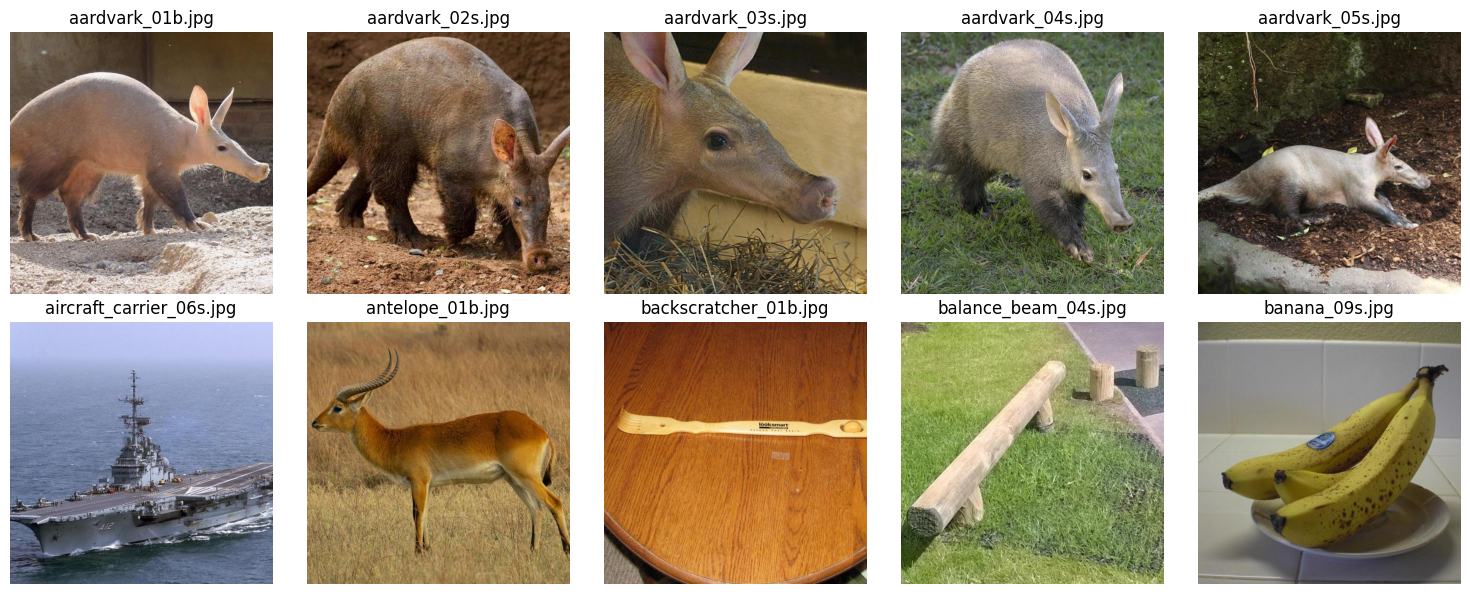

In [18]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):
    axes[0, i].imshow(Image.open(train_df.iloc[i]["path"]))
    axes[0, i].set_title(train_df.iloc[i]["filename"])
    axes[0, i].axis("off")

    axes[1, i].imshow(Image.open(test_df.iloc[i]["path"]))
    axes[1, i].set_title(test_df.iloc[i]["filename"])
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

## CLIP Embeddings

Extract image embeddings using a frozen CLIP ViT-B/16 model. Each image is represented by a 512-dimensional vector.

Model loading

In [19]:
clip_processor = CLIPImageProcessor.from_pretrained(CLIP_MODEL)
clip_model = CLIPModel.from_pretrained(CLIP_MODEL).to(device)

clip_model.eval()
clip_model.requires_grad_(False)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel(
  (text_model): CLIPTextModel(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1

Extracting CLIP embeddings in batches and applying **L2 normalization**

In [20]:
@torch.inference_mode()
def extract_clip_embeddings(paths):
  embeddings = []

  for i in tqdm(range(0, len(paths), BATCH_SIZE)):
      images = [Image.open(path).convert("RGB") for path in paths[i:i+BATCH_SIZE]]
      inputs = clip_processor(images=images, return_tensors="pt").to(device)

      features = clip_model.get_image_features(**inputs)
      if not isinstance(features, torch.Tensor):
          features = features.pooler_output

      features = F.normalize(features.float(), p=2, dim=-1)
      embeddings.append(features.cpu().numpy())

  return np.concatenate(embeddings, axis=0)

Train embeddings

In [21]:
clip_train = extract_clip_embeddings(train_df["path"].tolist())
print("CLIP train:", clip_train.shape)

  0%|          | 0/517 [00:00<?, ?it/s]

CLIP train: (16540, 512)


Test embeddings

In [22]:
clip_test = extract_clip_embeddings(test_df["path"].tolist())
print("CLIP test:", clip_test.shape)

  0%|          | 0/7 [00:00<?, ?it/s]

CLIP test: (200, 512)


Validate embedding dimensions, numerical values and L2 norms

In [23]:
assert clip_train.shape == (16540, 512)
assert clip_test.shape == (200, 512)

assert np.isfinite(clip_train).all()
assert np.isfinite(clip_test).all()

assert np.allclose(np.linalg.norm(clip_train, axis=1), 1, atol=1e-5)
assert np.allclose(np.linalg.norm(clip_test, axis=1), 1, atol=1e-5)

print("CLIP embeddings are valid")

CLIP embeddings are valid


Save CLIP embeddings as NumPy arrays (path /content/drive/MyDrive/Neural-Decoding/embeddings)

In [24]:
np.save(OUTPUT_DIR / "clip_train.npy", clip_train)
np.save(OUTPUT_DIR / "clip_test.npy", clip_test)

## DINOv2 Embeddings

Extract image embeddings using a frozen DINOv2 ViT-B/14 model. Each image is represented by a 768-dimensional CLS token embedding.

In [25]:
del clip_model
torch.cuda.empty_cache()

Model loading

In [26]:
dino_processor = AutoImageProcessor.from_pretrained(DINO_MODEL)
dino_model = Dinov2Model.from_pretrained(DINO_MODEL).to(device)
dino_model.eval()
dino_model.requires_grad_(False)

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Dinov2Model(
  (embeddings): Dinov2Embeddings(
    (patch_embeddings): Dinov2PatchEmbeddings(
      (projection): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (encoder): Dinov2Encoder(
    (layer): ModuleList(
      (0-11): 12 x Dinov2Layer(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (attention): Dinov2Attention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layer_scale1): Dinov2LayerScale()
        (drop_path): Identity()
        (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
        (mlp): Dinov2MLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, ou

Extracting DINOv2 embeddings in batches and applying **L2 normalization**

In [28]:
@torch.inference_mode()
def extract_dino_embeddings(paths):
  embeddings = []

  for i in tqdm(range(0, len(paths), BATCH_SIZE)):
      images = [Image.open(path).convert("RGB") for path in paths[i:i+BATCH_SIZE]]
      inputs = dino_processor(images=images, return_tensors="pt").to(device)

      #DINOv2 returns representations of all image tokens and we only take the first token — CLS token, which represents the image in general
      outputs = dino_model(**inputs)
      features = outputs.last_hidden_state[:, 0, :]

      features = F.normalize(features.float(), p=2, dim=-1)
      embeddings.append(features.cpu().numpy())

  return np.concatenate(embeddings, axis=0)

Train embeddings

In [29]:
dino_train = extract_dino_embeddings(train_df["path"].tolist())
print("DINOv2 train:", dino_train.shape)

  0%|          | 0/517 [00:00<?, ?it/s]

DINOv2 train: (16540, 768)


Test embeddings

In [30]:
dino_test = extract_dino_embeddings(test_df["path"].tolist())
print("DINOv2 test:", dino_test.shape)

  0%|          | 0/7 [00:00<?, ?it/s]

DINOv2 test: (200, 768)


Validate embedding dimensions, numerical values and L2 norms

In [31]:
assert dino_train.shape == (16540, 768)
assert dino_test.shape == (200, 768)

assert np.isfinite(dino_train).all()
assert np.isfinite(dino_test).all()

assert np.allclose(np.linalg.norm(dino_train, axis=1), 1, atol=1e-5)
assert np.allclose(np.linalg.norm(dino_test, axis=1), 1, atol=1e-5)

print("DINOv2 embeddings are valid")

DINOv2 embeddings are valid


Save DINOv2 embeddings as NumPy arrays

In [32]:
np.save(OUTPUT_DIR / "dino_train.npy", dino_train)
np.save(OUTPUT_DIR / "dino_test.npy", dino_test)

## Saving Metadata

Save image metadata to preserve the correspondence between embedding rows and EEG recordings.

In [34]:
train_df.drop(columns="path").to_csv(OUTPUT_DIR / "train_metadata.csv", index=False)
test_df.drop(columns="path").to_csv(OUTPUT_DIR / "test_metadata.csv", index=False)
for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name, round(file.stat().st_size / 1024**2, 2), "MB")

clip_test.npy 0.39 MB
clip_train.npy 32.3 MB
dino_test.npy 0.59 MB
dino_train.npy 48.46 MB
test_metadata.csv 0.01 MB
train_metadata.csv 0.56 MB


# Embedding Analysis
Compare CLIP and DINOv2 representation spaces using training images. Analyze cosine similarities, concept separation, nearest neighbors and embedding structure.

## Cosine Similarity Distribution

Compare cosine similarities between randomly sampled image pairs using the same pairs for both models.

In [35]:
rng = np.random.default_rng(42)

idx_a = rng.integers(0, len(train_df), size=100000)
idx_b = rng.integers(0, len(train_df), size=100000)

mask = idx_a != idx_b
idx_a = idx_a[mask]
idx_b = idx_b[mask]

print("Image pairs:", len(idx_a))

Image pairs: 99994


In [36]:
clip_sim = np.einsum("ij,ij->i", clip_train[idx_a], clip_train[idx_b])
dino_sim = np.einsum("ij,ij->i", dino_train[idx_a], dino_train[idx_b])

In [37]:
similarity_df = pd.DataFrame({
    "CLIP": clip_sim,
    "DINOv2": dino_sim
})

similarity_df.describe().round(4)

,CLIP,DINOv2
count,99994.0000,99994.0000
mean,0.5500,0.0120
std,0.0762,0.0491
min,0.1255,-0.1373
25%,0.5002,-0.0172
50%,0.5491,0.0073
75%,0.5998,0.0338
max,0.9312,0.9232


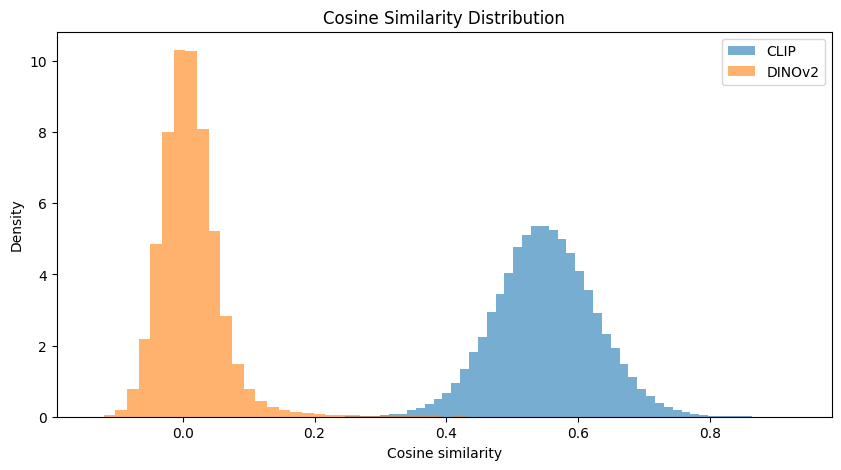

In [38]:
plt.figure(figsize=(10, 5))
plt.hist(clip_sim, bins=60, alpha=0.6, density=True, label="CLIP")
plt.hist(dino_sim, bins=60, alpha=0.6, density=True, label="DINOv2")
plt.xlabel("Cosine similarity")
plt.ylabel("Density")
plt.title("Cosine Similarity Distribution")
plt.legend()
plt.show()

**Findings:**

CLIP and DINOv2 exhibit substantially different embedding geometries. CLIP similarities are concentrated around 0.55, suggesting a more anisotropic representation space with a shared direction across image embeddings. In contrast, DINOv2 similarities are centered near zero, indicating that randomly sampled image embeddings are approximately orthogonal.

However, these differences do not necessarily imply that either model produces better representations or aligns better with EEG signals.

### Within vs Between Concepts

Compare cosine similarities between images of the same concept and images of different concepts.

Within-concept pairs

In [39]:
from itertools import combinations

within_pairs = []

for _, group in train_df.groupby("concept"):
    within_pairs.extend(combinations(group.index, 2))

within_pairs = np.array(within_pairs)
print("Within-concept pairs:", len(within_pairs))

Within-concept pairs: 74430


Between-concept pairs

In [40]:
concepts = train_df["concept"].to_numpy()

mask = concepts[idx_a] != concepts[idx_b]
between_pairs = np.column_stack((idx_a[mask], idx_b[mask]))

between_pairs = between_pairs[rng.choice(len(between_pairs), len(within_pairs), replace=False)]
print("Between-concept pairs:", len(between_pairs))

Between-concept pairs: 74430


Computing similarities

In [41]:
def pair_similarity(embeddings, pairs):
    return np.einsum("ij,ij->i", embeddings[pairs[:, 0]], embeddings[pairs[:, 1]])

clip_within = pair_similarity(clip_train, within_pairs)
clip_between = pair_similarity(clip_train, between_pairs)

dino_within = pair_similarity(dino_train, within_pairs)
dino_between = pair_similarity(dino_train, between_pairs)

Summary

In [43]:
concept_results = pd.DataFrame({
    "Model": ["CLIP", "DINOv2"],
    "Within concept": [clip_within.mean(), dino_within.mean()],
    "Between concepts": [clip_between.mean(), dino_between.mean()]
})

concept_results["Gap"] = concept_results["Within concept"] - concept_results["Between concepts"]
concept_results.round(4)

,Model,Within concept,Between concepts,Gap
0,CLIP,0.8066,0.5498,0.2568
1,DINOv2,0.5725,0.0117,0.5608


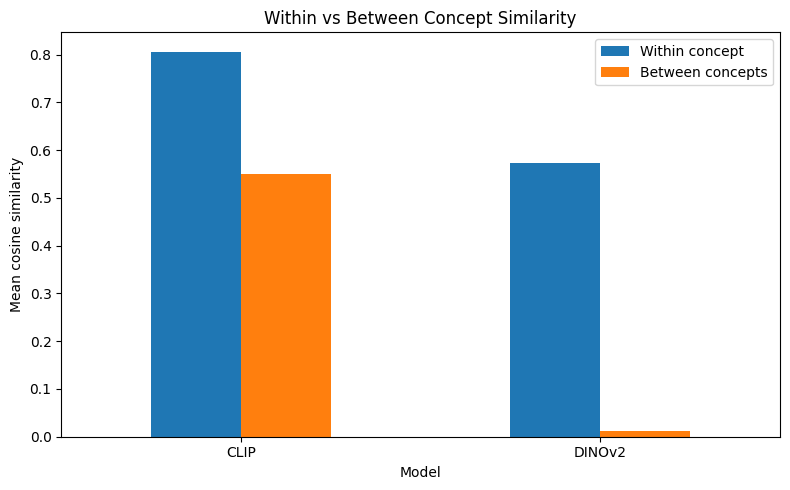

In [46]:
concept_results.set_index("Model")[["Within concept", "Between concepts"]].plot(kind="bar", figsize=(8, 5), rot=0)

plt.ylabel("Mean cosine similarity")
plt.title("Within vs Between Concept Similarity")
plt.legend()
plt.tight_layout()
plt.show()

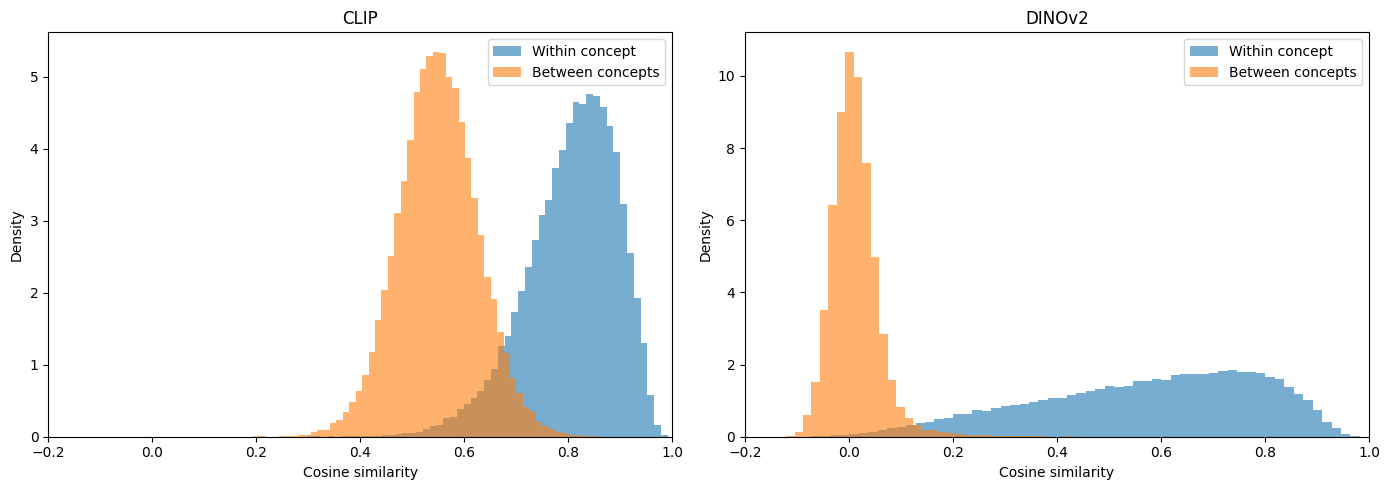

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, within, between, name in zip(axes, [clip_within, dino_within], [clip_between, dino_between], ["CLIP", "DINOv2"]):
    ax.hist(within, bins=60, alpha=0.6, density=True, label="Within concept")
    ax.hist(between, bins=60, alpha=0.6, density=True, label="Between concepts")
    ax.set_title(name)
    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")
    ax.set_xlim(-0.2, 1)
    ax.legend()

plt.tight_layout()
plt.show()

**Findings:**

Both models consider images of the same concept more similar than images of different concepts, but they do so differently.

- **CLIP** produces highly similar embeddings for images of the same concept (0.81 on average). However, even images of different concepts have relatively high similarity (0.55).
- **DINOv2** has lower average similarity within concepts (0.57), but images of different concepts have almost zero similarity (0.01).

DINOv2 shows a larger similarity gap (0.56 vs 0.26) and less overlap between the two distributions. This is particularly interesting because DINOv2 learns without any text supervision.

At the same time, CLIP is more consistent in how it represents images of the same concept, while DINOv2 shows greater variation.

It remains to be seen which of these representation spaces is easier to predict from EEG signals.

### Nearest Neighbors Analysis

Compare the nearest neighbors of the same query images in CLIP and DINOv2 embedding spaces using cosine similarity.

Finding nearest neighbors

In [47]:
def get_neighbors(embeddings, query_idx, k=5):
    similarities = embeddings @ embeddings[query_idx]
    similarities[query_idx] = -np.inf

    neighbors = np.argsort(similarities)[::-1][:k]

    return neighbors, similarities[neighbors]

In [48]:
def plot_neighbors(query_idx, k=5):
  fig, axes = plt.subplots(2, k+1, figsize=(15, 5))

  for row, embeddings, name in zip(range(2), [clip_train, dino_train], ["CLIP", "DINOv2"]):
      neighbors, scores = get_neighbors(embeddings, query_idx, k)

      axes[row, 0].imshow(Image.open(train_df.iloc[query_idx]["path"]))
      axes[row, 0].set_title(f"{name}\nQuery", fontweight="bold")
      axes[row, 0].axis("off")

      for col, (idx, score) in enumerate(zip(neighbors, scores), start=1):
          axes[row, col].imshow(Image.open(train_df.iloc[idx]["path"]))
          axes[row, col].set_title(f"{train_df.iloc[idx]['concept'][6:]}\n{score:.3f}")
          axes[row, col].axis("off")

  plt.tight_layout()
  plt.show()

Random query images

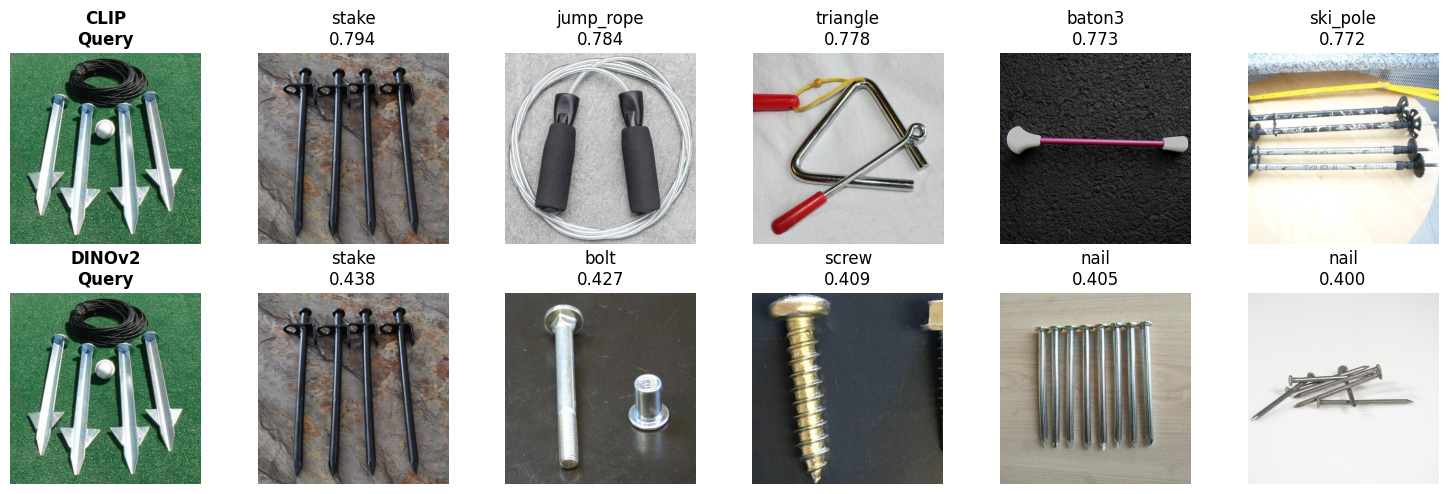

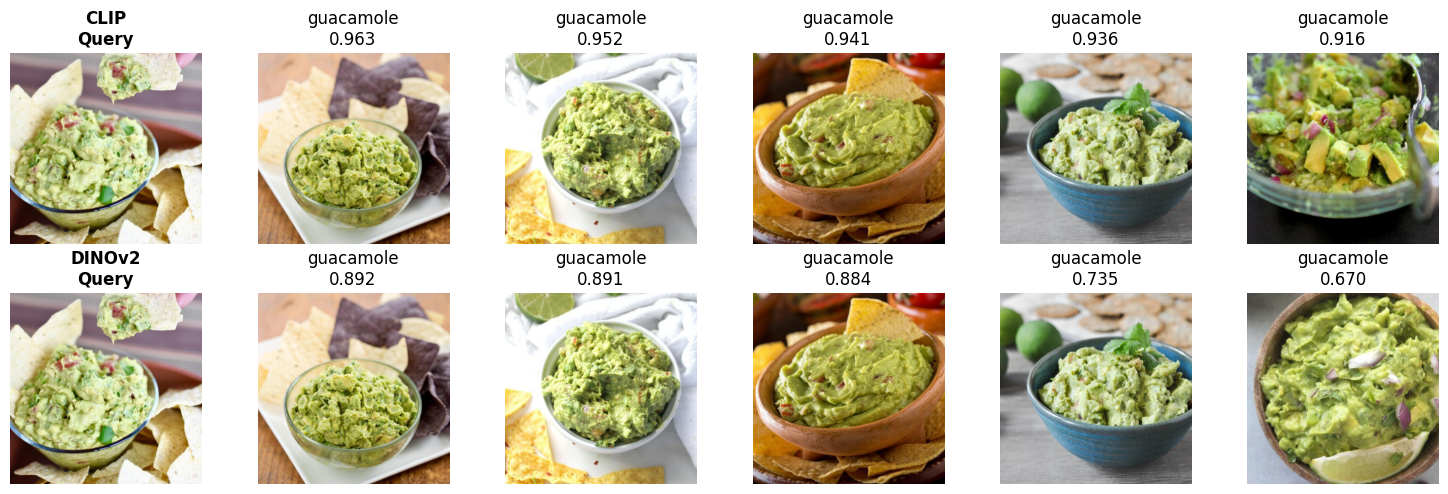

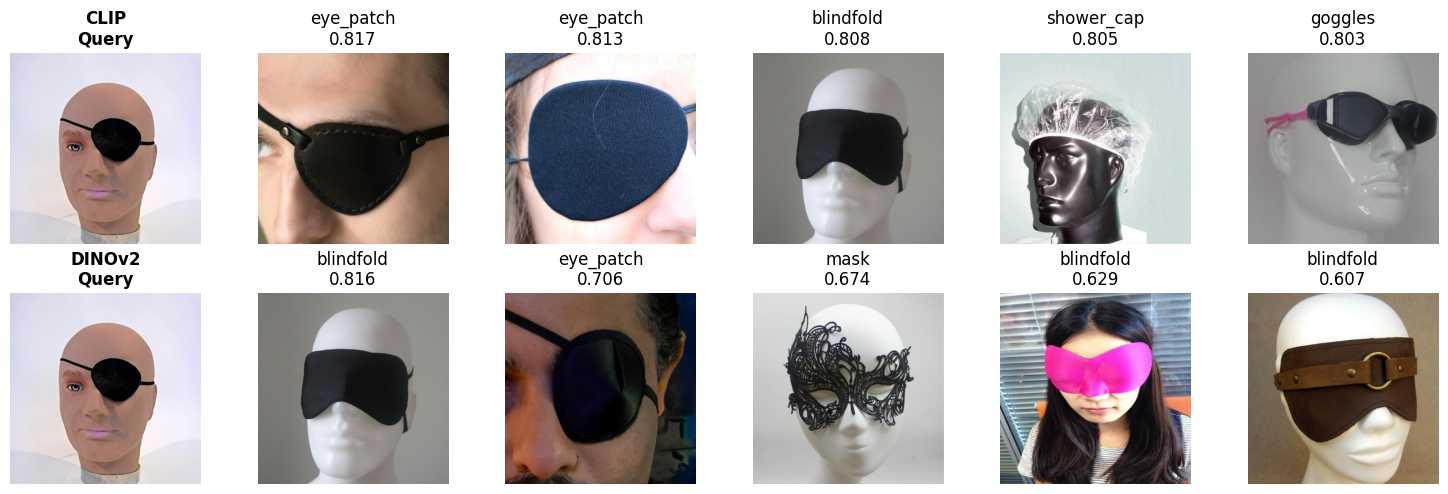

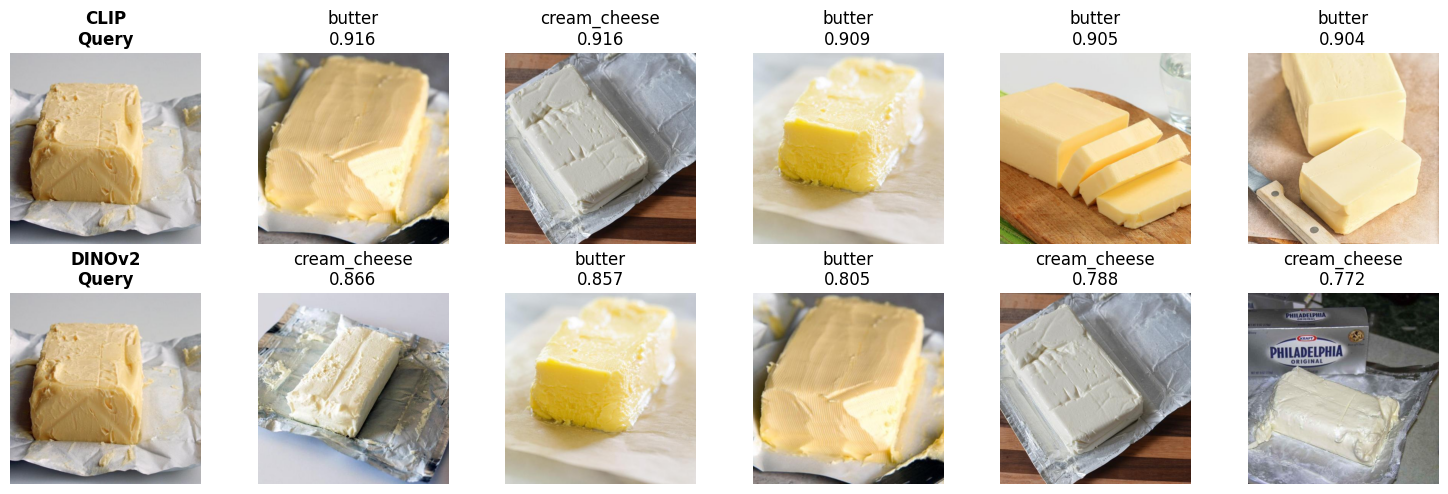

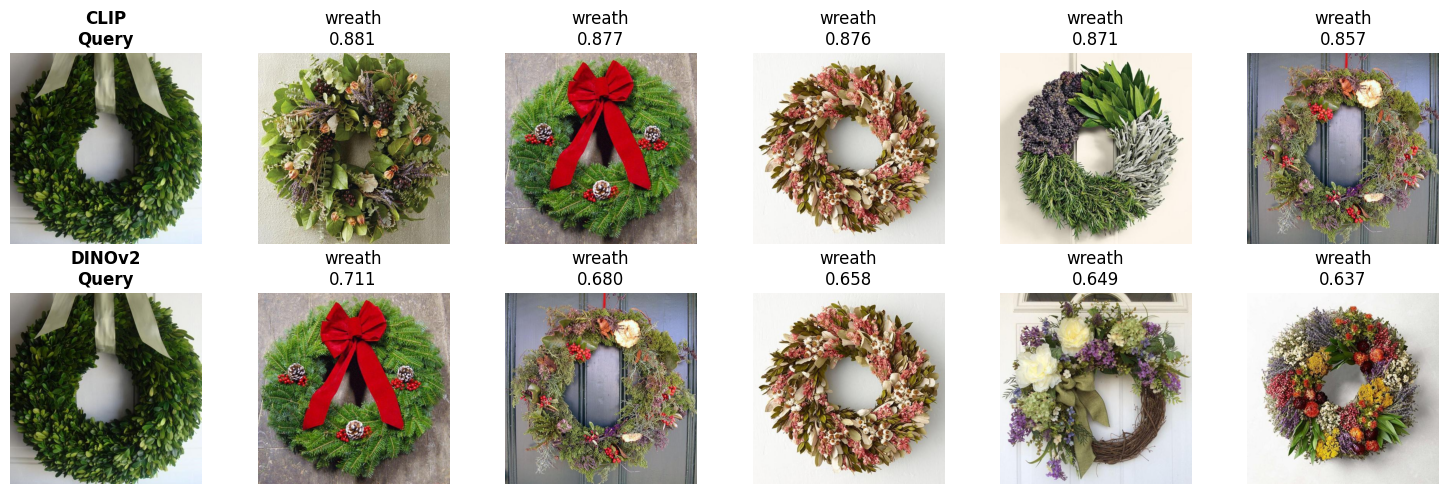

In [49]:
query_indices = rng.choice(len(train_df), size=5, replace=False)

for query_idx in query_indices:
    plot_neighbors(query_idx)

### Nearest Neighbor Concept Accuracy

We evaluate how often the nearest neighbors of an image
belong to the same concept across all training images.

- **Top-1 Accuracy:** the nearest neighbor belongs to the same concept.
- **Precision@5:** the proportion of the five nearest neighbors
  belonging to the same concept.
- **Hit@5:** at least one of the five nearest neighbors
  belongs to the same concept.

In [50]:
def evaluate_neighbors(embeddings, concepts, k=5):
  top1 = []
  precision5 = []
  hit5 = []

  embeddings = torch.from_numpy(embeddings).to(device)

  for i in tqdm(range(0, len(embeddings), 256)):
      batch = embeddings[i:i+256]

      similarities = batch @ embeddings.T

      # Exclude the query image itself
      rows = torch.arange(len(batch), device=device)
      similarities[rows, i+rows] = -torch.inf

      # Find the nearest neighbors
      neighbors = similarities.topk(k, dim=1).indices.cpu().numpy()

      # Check whether neighbors belong to the same concept
      matches = concepts[neighbors] == concepts[i:i+len(batch), None]

      top1.extend(matches[:, 0])
      precision5.extend(matches.mean(axis=1))
      hit5.extend(matches.any(axis=1))

  return np.mean(top1), np.mean(precision5), np.mean(hit5)

Evaluation

In [51]:
concepts = train_df["concept"].to_numpy()

neighbor_results = pd.DataFrame([evaluate_neighbors(clip_train, concepts),evaluate_neighbors(dino_train, concepts)],
    index=["CLIP", "DINOv2"],
    columns=["Top-1 Accuracy", "Precision@5", "Hit@5"])
(neighbor_results * 100).round(2)

  0%|          | 0/65 [00:00<?, ?it/s]

  0%|          | 0/65 [00:00<?, ?it/s]

,Top-1 Accuracy,Precision@5,Hit@5
CLIP,78.23,65.22,92.50
DINOv2,86.21,76.85,95.15


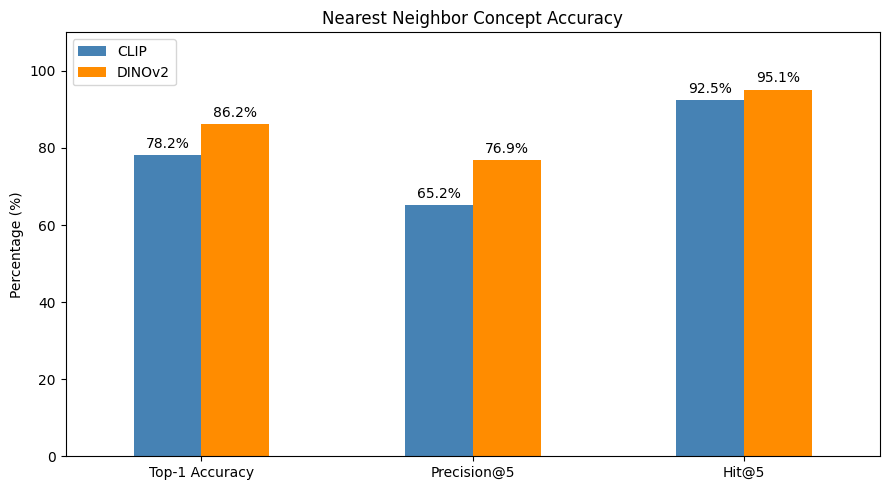

In [52]:
ax = (neighbor_results.T * 100).plot(
    kind="bar",
    figsize=(9, 5),
    rot=0,
    color=["steelblue", "darkorange"]
)

ax.set_title("Nearest Neighbor Concept Accuracy")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 110)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

**Findings:**

Both models perform well in nearest neighbor retrieval, but DINOv2 outperforms CLIP across all three metrics. For 86.2% of images, DINOv2 retrieves a nearest neighbor from the same concept, compared to 78.2% for CLIP. DINOv2 also retrieves more images of the correct concept among the five nearest neighbors (76.9% vs 65.2%).

These results show that images of the same concept are better grouped in the DINOv2 embedding space. However, this does not necessarily mean that DINOv2 embeddings are easier to predict from EEG signals.

### PCA Visualization

We use Principal Component Analysis (PCA) to visualize
the embedding spaces in two dimensions.

We randomly select 10 concepts and visualize all 10 images
of each concept using the same images for both models.
PCA is fitted separately on the full training embeddings
of each model.

In [53]:
from sklearn.decomposition import PCA

clip_pca = PCA(n_components=2)
dino_pca = PCA(n_components=2)

clip_2d = clip_pca.fit_transform(clip_train)
dino_2d = dino_pca.fit_transform(dino_train)

print("CLIP explained variance:", clip_pca.explained_variance_ratio_)
print("DINOv2 explained variance:", dino_pca.explained_variance_ratio_)

CLIP explained variance: [0.06061716 0.0525705 ]
DINOv2 explained variance: [0.00959924 0.0083285 ]


In [54]:
rng = np.random.default_rng(42)

selected_concepts = rng.choice(
    train_df["concept"].unique(),
    size=10,
    replace=False
)

selected_concepts

array(['00142_bolt', '01274_showerhead', '00147_book', '01079_polygraph',
       '00724_icepick', '00715_hula_hoop', '01153_reindeer', '00156_bow2',
       '00334_coffee_table', '01417_sweater'], dtype=object)

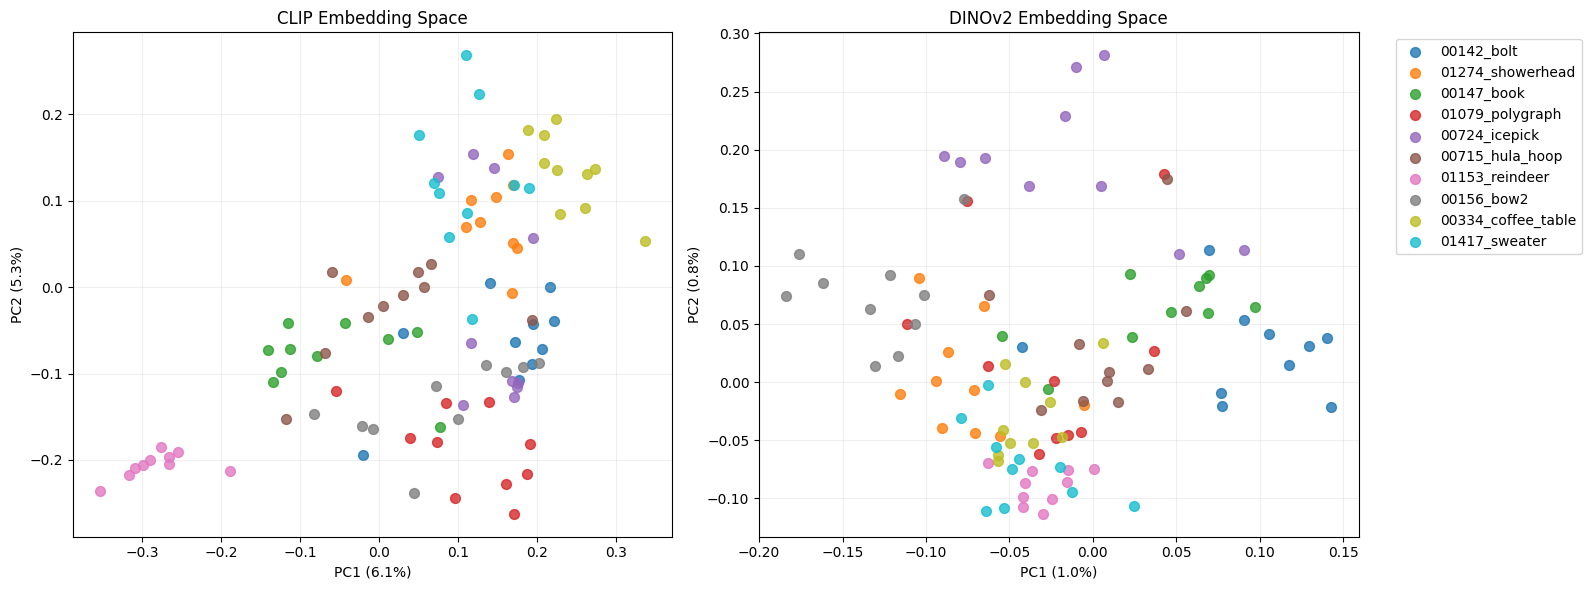

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = plt.cm.tab10.colors

for ax, embeddings_2d, pca, model_name in [(axes[0], clip_2d, clip_pca, "CLIP"), (axes[1], dino_2d, dino_pca, "DINOv2")]:
    for concept, color in zip(selected_concepts, colors):
        mask = train_df["concept"].to_numpy() == concept

        ax.scatter(
            embeddings_2d[mask, 0],
            embeddings_2d[mask, 1],
            label=concept,
            color=color,
            alpha=0.8,
            s=50)

    variance = pca.explained_variance_ratio_ * 100
    ax.set_title(f"{model_name} Embedding Space")
    ax.set_xlabel(f"PC1 ({variance[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({variance[1]:.1f}%)")
    ax.grid(alpha=0.2)

axes[1].legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

**Findings:**

Both models show some clustering of images belonging to the same concept, although several concepts overlap. The first two principal components explain 11.4% of the variance in CLIP and only 1.8% in DINOv2. This suggests that variance is less concentrated in the leading principal components of DINOv2. Since both projections capture only a small portion of the total variance, the plots cannot reliably show which model separates concepts better in the original embedding space

Cumulative explained variance plot

In [57]:
clip_pca_full = PCA().fit(clip_train)
dino_pca_full = PCA().fit(dino_train)

clip_cumulative = np.cumsum(clip_pca_full.explained_variance_ratio_)
dino_cumulative = np.cumsum(dino_pca_full.explained_variance_ratio_)

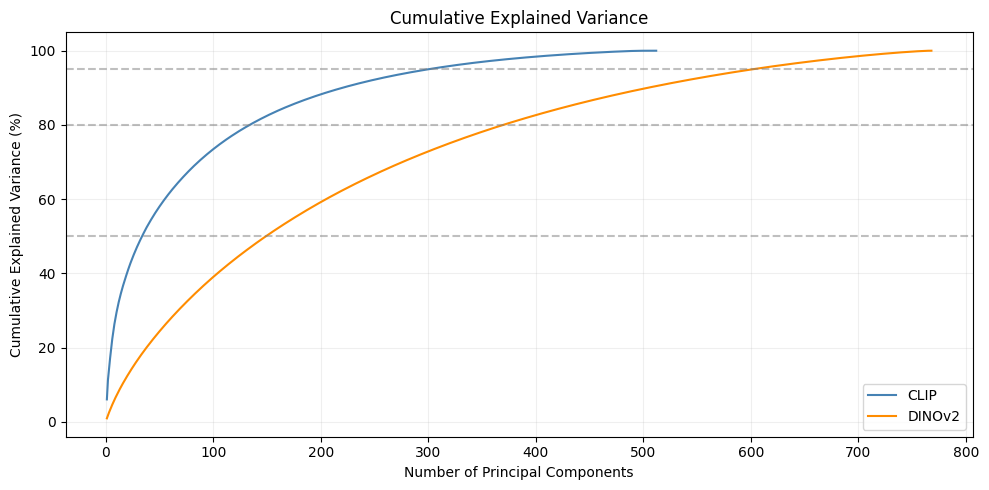

In [58]:
plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(clip_cumulative) + 1),
    clip_cumulative * 100,
    label="CLIP",
    color="steelblue"
)

plt.plot(
    np.arange(1, len(dino_cumulative) + 1),
    dino_cumulative * 100,
    label="DINOv2",
    color="darkorange"
)

for threshold in [50, 80, 95]:
    plt.axhline(threshold, color="gray", linestyle="--", alpha=0.5)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Relative number of components

In [60]:
thresholds = [0.5, 0.8, 0.95]

variance_results = pd.DataFrame({
    "CLIP": [np.searchsorted(clip_cumulative, t) + 1 for t in thresholds],
    "DINOv2": [np.searchsorted(dino_cumulative, t) + 1 for t in thresholds]}, index=["50%", "80%", "95%"])

relative_variance_results = (variance_results / pd.Series({
        "CLIP": clip_train.shape[1],
        "DINOv2": dino_train.shape[1]
    }) * 100).round(2)

relative_variance_results

,CLIP,DINOv2
50%,6.64,19.40
80%,26.17,48.18
95%,58.59,78.39


CLIP requires fewer principal components to explain the same amount of variance. For example, 80% of the variance is captured by 26.2% of CLIP components, compared to 48.2% for DINOv2. This suggests that CLIP embeddings can be compressed more effectively using PCA

### Representational Similarity Analysis (RSA)

We compare the structure of CLIP and DINOv2 embedding spaces
using Representational Dissimilarity Matrices (RDMs).

We calculate pairwise cosine distances between the same images
and use Spearman correlation to measure how similarly
the two models rank these distances.

In [61]:
from scipy.stats import spearmanr

rng = np.random.default_rng(42)

rsa_indices = rng.choice(len(train_df), size=2000, replace=False)

clip_sample = clip_train[rsa_indices]
dino_sample = dino_train[rsa_indices]

clip_rdm = 1 - clip_sample @ clip_sample.T
dino_rdm = 1 - dino_sample @ dino_sample.T

In [62]:
upper_indices = np.triu_indices(len(rsa_indices), k=1)

clip_distances = clip_rdm[upper_indices]
dino_distances = dino_rdm[upper_indices]

rsa_correlation, _ = spearmanr(clip_distances, dino_distances)

print("Number of image pairs:", len(clip_distances))
print(f"Spearman correlation: {rsa_correlation:.4f}")

Number of image pairs: 1999000
Spearman correlation: 0.1939


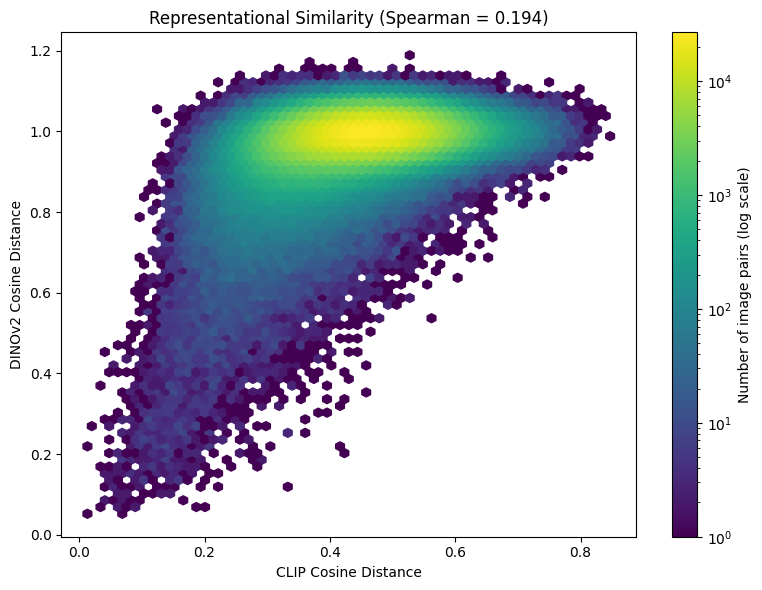

In [63]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    clip_distances,
    dino_distances,
    gridsize=60,
    bins="log",
    cmap="viridis",
    mincnt=1
)

plt.colorbar(label="Number of image pairs (log scale)")
plt.xlabel("CLIP Cosine Distance")
plt.ylabel("DINOv2 Cosine Distance")
plt.title(f"Representational Similarity (Spearman = {rsa_correlation:.3f})")

plt.tight_layout()
plt.show()

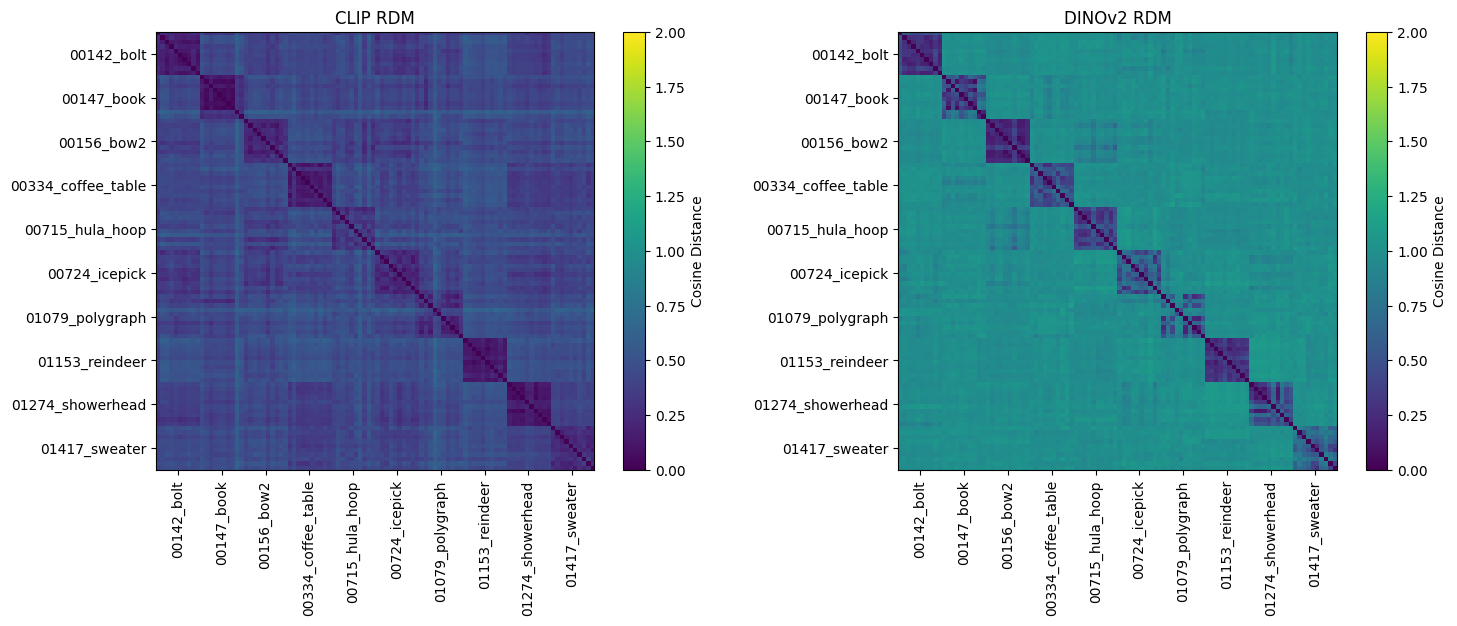

In [64]:
rdm_indices = (
    train_df[train_df["concept"].isin(selected_concepts)]
    .sort_values("concept")
    .index.to_numpy()
)

clip_rdm_vis = 1 - clip_train[rdm_indices] @ clip_train[rdm_indices].T
dino_rdm_vis = 1 - dino_train[rdm_indices] @ dino_train[rdm_indices].T

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

concept_labels = sorted(selected_concepts)
tick_positions = np.arange(len(concept_labels)) * 10 + 4.5

for ax, rdm, model_name in [
    (axes[0], clip_rdm_vis, "CLIP"),
    (axes[1], dino_rdm_vis, "DINOv2")
]:
    im = ax.imshow(rdm, cmap="viridis", vmin=0, vmax=2)

    ax.set_title(f"{model_name} RDM")
    ax.set_xticks(tick_positions)
    ax.set_yticks(tick_positions)
    ax.set_xticklabels(concept_labels, rotation=90)
    ax.set_yticklabels(concept_labels)

    fig.colorbar(im, ax=ax, label="Cosine Distance")

plt.tight_layout()
plt.show()

The low Spearman correlation (0.194) shows that CLIP and DINOv2 measure similarity between images quite differently. Both models group images of the same concept together, but DINOv2 shows a clearer separation between different concepts.